In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("postings.csv")

In [3]:
df.head(5) 

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [4]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  object 
 2   title                       123849 non-null  object 
 3   description                 123842 non-null  object 
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   object 
 6   location                    123849 non-null  object 
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  object 
 12  applies                     23320 non-null   float64
 13  original_liste

In [5]:
tech_df = df[
    df["title"].str.contains(
        "Software Engineer"
        "|Software Developer"
        "|Data Analyst"
        "|Data Scientist"
        "|Data Engineer"
        "|Machine Learning Engineer"
        "|DevOps Engineer"
        "|Business Intelligence Analyst"
        "|Cybersecurity Analyst"
        "|Cloud Engineer"
        "|Database Administrator"
        "|Systems Administrator"
        "|QA Engineer",
        case=False,
        na=False
    )
]

In [6]:
tech_df.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 3310 entries, 22 to 123845
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   job_id                      3310 non-null   int64  
 1   company_name                3281 non-null   object 
 2   title                       3310 non-null   object 
 3   description                 3310 non-null   object 
 4   max_salary                  1001 non-null   float64
 5   pay_period                  1063 non-null   object 
 6   location                    3310 non-null   object 
 7   company_id                  3281 non-null   float64
 8   views                       3273 non-null   float64
 9   med_salary                  62 non-null     float64
 10  min_salary                  1001 non-null   float64
 11  formatted_work_type         3310 non-null   object 
 12  applies                     1675 non-null   float64
 13  original_listed_time        3310 no

In [7]:
tech_df = tech_df[
    ["job_id", "title", "company_name", "description", "location", "formatted_experience_level", "formatted_work_type"]
].copy()

In [8]:
tech_df.isna().sum()

job_id                          0
title                           0
company_name                   29
description                     0
location                        0
formatted_experience_level    916
formatted_work_type             0
dtype: int64

In [9]:
tech_df.head(15) 

,job_id,title,company_name,description,location,formatted_experience_level,formatted_work_type
22,133130219,Software Engineer,NaN,"Education Bachelor's degree in software, math,...",Los Angeles Metropolitan Area,NaN,Full-time
26,175485704,Software Engineer,GOYT,Job Description:GOYT is seeking a skilled and ...,"Denver, CO",NaN,Part-time
181,3586167732,Senior Software Engineer,StyleAI,"StyleAI is the AI-powered, all-in-one unified ...",San Francisco Bay Area,NaN,Full-time
283,3742692445,Sr Data Engineer with Kafka,ZenithMinds Inc,Data Engineer with Kafka (W2 Only)💯% Remote\nM...,"Austin, TX",NaN,Full-time
360,3797449314,Cloud Platform/ Big Data Engineer,"Subaru Research and Development, Inc",About Subaru Research and Development:Do you c...,"Michigan, United States",Entry level,Full-time
366,3800272386,Data Science Software Engineer,Sovrinti,Company Overview Sovrinti is a full-service en...,United States,NaN,Full-time
367,3800989742,Data Engineer/ETL,SilverSpace Technologies Inc,"Responsibilities:Develop new features, fix bug...","Hartford, CT",NaN,Contract
373,3803052628,Flight Software Engineer,Insight Global,Must Haves:10-15 years of experience with C++ ...,"Webster, TX",Mid-Senior level,Full-time
389,3813645405,Data Analyst,Tenazx Inc,Job Title: Data AnalystDuration: ContractLocat...,"Queens, NY",NaN,Contract
399,3815847830,Staff Software Engineer (AHT),Northrop Grumman,"At Northrop Grumman, our employees have incred...","Los Angeles, California, United States",Mid-Senior level,Full-time


In [10]:
print(df["description"].iloc[0])

Job descriptionA leading real estate firm in New Jersey is seeking an administrative Marketing Coordinator with some experience in graphic design. You will be working closely with our fun, kind, ambitious members of the sales team and our dynamic executive team on a daily basis. This is an opportunity to be part of a fast-growing, highly respected real estate brokerage with a reputation for exceptional marketing and extraordinary culture of cooperation and inclusion.Who you are:You must be a well-organized, creative, proactive, positive, and most importantly, kind-hearted person. Please, be responsible, respectful, and cool-under-pressure. Please, be proficient in Adobe Creative Cloud (Indesign, Illustrator, Photoshop) and Microsoft Office Suite. Above all, have fantastic taste and be a good-hearted, fun-loving person who loves working with people and is eager to learn.Role:Our office is a fast-paced environment. You’ll work directly with a Marketing team and communicate daily with oth

In [11]:
print(tech_df["description"].head(10).to_string(index=False))

Education Bachelor's degree in software, math, ...
Job Description:GOYT is seeking a skilled and m...
StyleAI is the AI-powered, all-in-one unified m...
Data Engineer with Kafka (W2 Only)💯% Remote\nMi...
About Subaru Research and Development:Do you ca...
Company Overview Sovrinti is a full-service ene...
Responsibilities:Develop new features, fix bugs...
Must Haves:10-15 years of experience with C++ d...
Job Title: Data AnalystDuration: ContractLocati...
At Northrop Grumman, our employees have incredi...


In [12]:
tech_df.isna().sum() 

job_id                          0
title                           0
company_name                   29
description                     0
location                        0
formatted_experience_level    916
formatted_work_type             0
dtype: int64

In [13]:
tech_df["job_id"].duplicated().sum()

np.int64(0)

In [14]:
tech_df["job_category"] = tech_df["title"].copy() 

In [15]:
tech_df["description"].str.len().value_counts()

description
1484    39
1503    34
1453    31
1331    20
2431    11
        ..
1229     1
4296     1
1822     1
9438     1
5402     1
Name: count, Length: 2442, dtype: int64

### What are the metrics of job descriptions across postings? 

In [16]:
k = tech_df["description"]
print(f"dataset postings: {len(tech_df):>10,}")
print(f"job postings with a description {k.count():>10,}")
print("\n")

print(f"median character length of a job description: {k.str.len().median():.2f}")
print(f"mean character length of a job description: {k.str.len().mean():.2f}")
print("\n")
print(f"shortest job description in the dataset: {k.str.len().min():.2f}")
print(f"longest job description in the dataset: {k.str.len().max():.2f}")



dataset postings:      3,310
job postings with a description      3,310


median character length of a job description: 3459.50
mean character length of a job description: 3718.15


shortest job description in the dataset: 41.00
longest job description in the dataset: 15768.00


### What is the distribution of different job skills across companies?

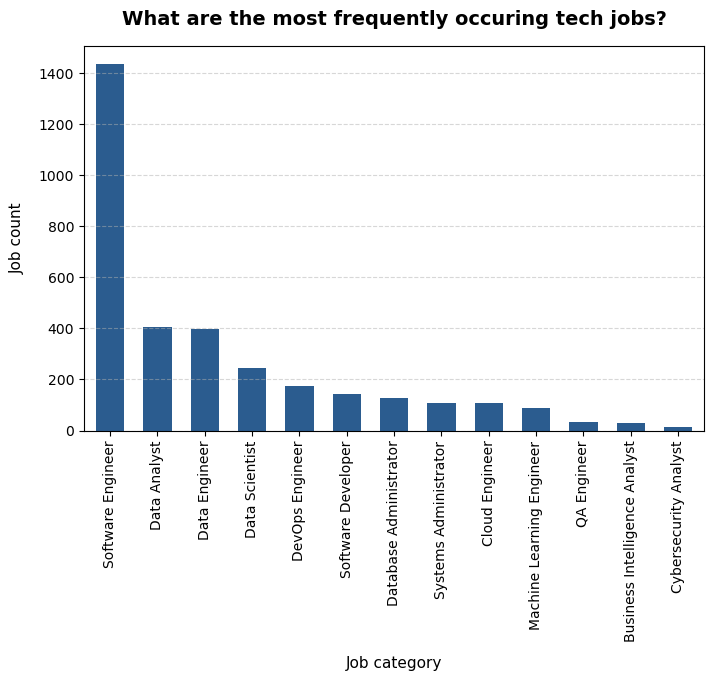

In [17]:
job_roles = ["Software Engineer",
              "Software Developer", 
              "Data Analyst", 
              "Data Scientist", 
              "Data Engineer", 
              "Machine Learning Engineer", 
              "DevOps Engineer", 
              "Business Intelligence Analyst",
              "Cybersecurity Analyst", 
              "Cloud Engineer", 
              "Database Administrator", 
              "Systems Administrator", 
              "QA Engineer"]

for job in job_roles:
    mask = tech_df["title"].str.contains(job, case = False, na = False ) 
    tech_df.loc[mask, "job_category"] = job

job_counts = tech_df["job_category"].value_counts() 

ax = job_counts.plot(
    kind = "bar", 
    color = "#2b5c8f",
    width = 0.6,
    legend = False,
    figsize = (8,5)
)

ax.set_title("What are the most frequently occuring tech jobs?", fontsize = 14, pad = 15, weight = "bold") 
ax.set_xlabel("Job category", fontsize = 11, labelpad = 10)
ax.set_ylabel("Job count", fontsize = 11, labelpad = 10)
ax.grid(axis = "y", linestyle = "--", alpha = 0.5)
ax.tick_params(axis='x', labelrotation=90)
plt.show() 


In [18]:
tech_df["job_category"].value_counts()

job_category
Software Engineer                1435
Data Analyst                      407
Data Engineer                     398
Data Scientist                    246
DevOps Engineer                   173
Software Developer                143
Database Administrator            128
Systems Administrator             109
Cloud Engineer                    108
Machine Learning Engineer          88
QA Engineer                        32
Business Intelligence Analyst      28
Cybersecurity Analyst              15
Name: count, dtype: int64

### How frequently does python appear across different job roles? 

In [19]:
tech_df["python_flag"] = tech_df["description"].str.contains("Python", case = False)
grouped_jobs = tech_df.groupby("job_category")
grouped_jobs = grouped_jobs["python_flag"].mean()
grouped_jobs *= 100

print(grouped_jobs)

job_category
Business Intelligence Analyst    39.285714
Cloud Engineer                   31.481481
Cybersecurity Analyst            13.333333
Data Analyst                     35.872236
Data Engineer                    71.608040
Data Scientist                   88.211382
Database Administrator           11.718750
DevOps Engineer                  49.710983
Machine Learning Engineer        85.227273
QA Engineer                      21.875000
Software Developer               56.643357
Software Engineer                42.439024
Systems Administrator            15.596330
Name: python_flag, dtype: float64


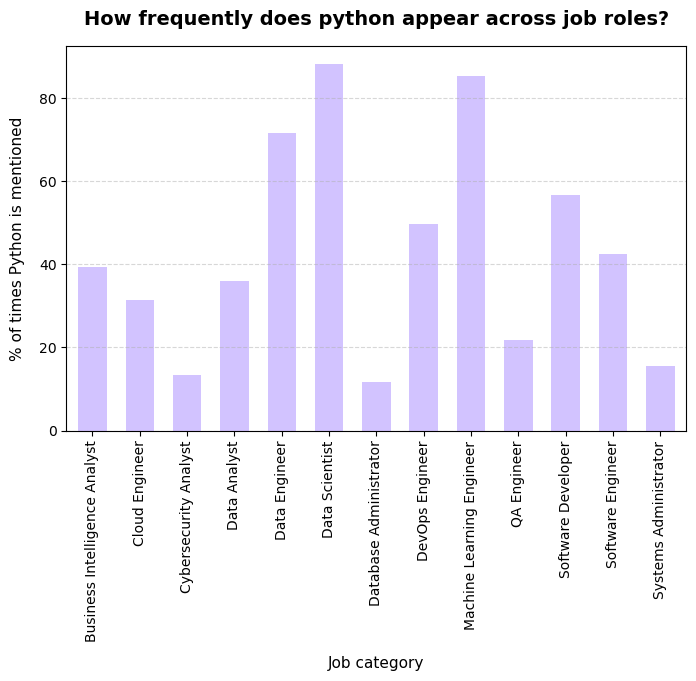

In [20]:
ax = grouped_jobs.plot(
    kind = "bar", 
    color = "#7a4eff56",
    width = 0.6,
    legend = False,
    figsize = (8,5)
)

ax.set_title("How frequently does python appear across job roles?", fontsize = 14, pad = 15, weight = "bold") 
ax.set_xlabel("Job category", fontsize = 11, labelpad = 10)
ax.set_ylabel("% of times Python is mentioned", fontsize = 11, labelpad = 10)
ax.grid(axis = "y", linestyle = "--", alpha = 0.5)
ax.tick_params(axis='x', labelrotation=90)
plt.show() 


In [21]:
cols = ["title", "description", "location"]
for col in cols:
    col_str = tech_df[col].str.len()
    Q1 = col_str.quantile(0.25)
    Q3 = col_str.quantile(0.75)

    IQR = Q3 - Q1 
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = tech_df[(col_str < lower_bound) | (col_str > upper_bound)]
    display(outliers) 

    count = ((col_str < lower_bound) | (col_str > upper_bound)).sum()
    print(f" {col} has {count} outliers")




,job_id,title,company_name,description,location,formatted_experience_level,formatted_work_type,job_category,python_flag
1787,3884439345,Software Engineer for global computer software...,OSI Engineering,Software Engineer for global computer software...,"Redmond, WA",Mid-Senior level,Contract,Software Engineer,False
1864,3884440051,"IT Systems Administrator (Windows, Linux) - Mu...",DKKD Staffing,"IT Systems Administrator, Services – Hybrid – ...","El Segundo, CA",Associate,Full-time,Systems Administrator,False
2688,3884809680,Hardcore Dataplane Software Engineer. If you t...,Hedgehog,This is a hard-core coding position. The ideal...,United States,NaN,Full-time,Software Engineer,False
3834,3884855862,Senior Data Engineer (Property Reinsurance/ Sp...,Avesta Computer Services,Our client is seeking talented and intellectua...,United States,Mid-Senior level,Full-time,Data Engineer,True
7751,3885852341,C++ Algo Software Engineer - Chicago/New York-...,Jobs via eFinancialCareers,Summary\n\nNot your standard financial service...,"Chicago, IL",Entry level,Full-time,Software Engineer,True
...,...,...,...,...,...,...,...,...,...
112726,3905660238,R&D Computer Science Software Engineer/Satelli...,Sandia National Laboratories,About Sandia\n\nSandia National Laboratories i...,"Albuquerque, NM",NaN,Full-time,Software Engineer,True
116438,3905869090,Software Engineer - Zero Trust Client (low-lev...,Cloudflare,"About Us\n\nAt Cloudflare, we have our eyes se...",United States,Associate,Full-time,Software Engineer,True
117303,3905884349,Network Architect and Systems Administrator (c...,Motion Recruitment,Our client is looking for a Network Architect ...,"Murray Hill, NJ",Mid-Senior level,Contract,Systems Administrator,True
117735,3906074575,Senior Oracle Database Administrator (Senior I...,City of Phoenix,"ABOUT THIS POSITIONWith more than 14,000 emplo...","Phoenix, AZ",Associate,Full-time,Database Administrator,True


 title has 91 outliers


,job_id,title,company_name,description,location,formatted_experience_level,formatted_work_type,job_category,python_flag
1814,3884439454,Sr. Procurement Data Analyst,Republic Services,"About The Company\n\nRepublic Services, Inc. (...","Phoenix, AZ",NaN,Full-time,Data Analyst,False
12933,3887710362,Database Administrator I,N.C. Department of Information Technology,Description Of Work\n\nLooking to take the nex...,"Wake County, NC",Entry level,Full-time,Database Administrator,False
14794,3887881849,Data Scientist - Clearance Required with Secur...,ClearanceJobs,Overview LMI is a consultancy dedicated to pow...,"Quantico, VA",Entry level,Full-time,Data Scientist,False
14868,3887883818,Unix Systems Administrator with Security Clear...,ClearanceJobs,Diligent Consulting is searching for a full-ti...,"Washington, DC",Entry level,Full-time,Systems Administrator,False
14939,3887885428,"Cloud Engineer, Senior with Security Clearance",ClearanceJobs,"Job Number: R0194025 Cloud Engineer, Senior\n\...","McLean, VA",Mid-Senior level,Part-time,Cloud Engineer,True
18348,3888933774,Data Engineer - All Levels,FedEx Dataworks,Job Description\n\nDuties for this role includ...,United States,NaN,Full-time,Data Engineer,True
19520,3889103440,"Staff Data Scientist, SSP.",InMobi,The InMobi Story\n\nWe like big challenges. Bu...,"San Mateo, CA",NaN,Full-time,Data Scientist,True
28009,3891804948,IT Specialist (Cloud Engineer),DC Department of Human Resources,There is only one city in the country that can...,"Long Beach, California, United States",Entry level,Full-time,Cloud Engineer,True
96365,3904946292,"Data Engineer, Senior with Security Clearance",ClearanceJobs,"Job Number: R0189836 Data Engineer, Senior\n\n...","Fort Belvoir, VA",Mid-Senior level,Part-time,Data Engineer,True
101916,3905254732,Oracle Database Administrator,Organizational Partners Consulting Group (OP C...,Oracle Database Administrator Location: Lansi...,"Lansing, MI",Entry level,Contract,Database Administrator,False


 description has 15 outliers


,job_id,title,company_name,description,location,formatted_experience_level,formatted_work_type,job_category,python_flag
22,133130219,Software Engineer,NaN,"Education Bachelor's degree in software, math,...",Los Angeles Metropolitan Area,NaN,Full-time,Software Engineer,False
181,3586167732,Senior Software Engineer,StyleAI,"StyleAI is the AI-powered, all-in-one unified ...",San Francisco Bay Area,NaN,Full-time,Software Engineer,False
360,3797449314,Cloud Platform/ Big Data Engineer,"Subaru Research and Development, Inc",About Subaru Research and Development:Do you c...,"Michigan, United States",Entry level,Full-time,Data Engineer,True
399,3815847830,Staff Software Engineer (AHT),Northrop Grumman,"At Northrop Grumman, our employees have incred...","Los Angeles, California, United States",Mid-Senior level,Full-time,Software Engineer,False
483,3841003722,Senior Data Engineer/Analyst - Full Time,NaN,"Job Type: Full-Time, Permanent \nResponsibilit...","California, United States",NaN,Full-time,Data Engineer,False
...,...,...,...,...,...,...,...,...,...
118178,3906091847,Data Analyst,Vertisystem,We're currently recruiting for the position of...,"Pennsylvania, United States",Mid-Senior level,Contract,Data Analyst,True
118270,3906092875,Cybersecurity Analyst II,Texas Health and Human Services,Performs advanced and/or supervisory cybersecu...,"Austin, Texas Metropolitan Area",Associate,Full-time,Cybersecurity Analyst,False
118302,3906093549,Senior Software Engineer,Selby Jennings,High Frequency Trading Firm looking to bring o...,"New York, United States",Mid-Senior level,Full-time,Software Engineer,True
119223,3906223439,Data Engineering Lead (Permanent Direct Hire),Bayforce,Position: Data Engineering Lead (Permanent Dir...,"New York, United States",Mid-Senior level,Full-time,Data Engineer,True


 location has 363 outliers


In [22]:
tech_df.shape

(3310, 9)

In [23]:
(tech_df == 0).sum() 

job_id                           0
title                            0
company_name                     0
description                      0
location                         0
formatted_experience_level       0
formatted_work_type              0
job_category                     0
python_flag                   1725
dtype: int64

In [24]:
tech_df.duplicated().sum() 

np.int64(0)

In [25]:
tech_df["formatted_experience_level"].value_counts() 

formatted_experience_level
Mid-Senior level    1602
Entry level          539
Associate            196
Director              30
Internship            23
Executive              4
Name: count, dtype: int64

In [26]:
tech_df["formatted_work_type"].value_counts() 

formatted_work_type
Full-time     2417
Contract       794
Part-time       39
Internship      36
Other           11
Temporary        9
Volunteer        4
Name: count, dtype: int64

In [27]:
tech_df = tech_df.rename(columns={"formatted_work_type": "work_type", "formatted_experience_level": "experience_level"})

In [28]:
tech_df[tech_df.duplicated(keep=False)]

,job_id,title,company_name,description,location,experience_level,work_type,job_category,python_flag


In [29]:
tech_df = tech_df.drop_duplicates() 

In [30]:
tech_df.isna().sum()

job_id                0
title                 0
company_name         29
description           0
location              0
experience_level    916
work_type             0
job_category          0
python_flag           0
dtype: int64

In [31]:
(tech_df == 0).sum() 

job_id                 0
title                  0
company_name           0
description            0
location               0
experience_level       0
work_type              0
job_category           0
python_flag         1725
dtype: int64

In [32]:
tech_df.to_csv("tech_data.csv")

In [33]:
print(tech_df["description"].iloc[0])

Education Bachelor's degree in software, math, or science required Job Skills Analytical skills, group work, knowledge of intended audience, understanding of different roles
